# Underwater Image Restoration

## Assignment 2

### Objective
Improve underwater photographs affected by color distortion,
haze and reduced contrast.

### Techniques
1. Gray-world white balance
2. Contrast Limited Adaptive Histogram Equalization (CLAHE)
3. Image sharpening

### Technologies
Python, OpenCV, NumPy, Pillow, Matplotlib and Jupyter Notebook.

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from pathlib import Path

print("Libraries imported successfully.")


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully.


In [4]:
#Implement the algorithm
def restore_underwater_image(
    image_rgb,
    color_strength=0.5,
    contrast_strength=2.0,
    sharpening_strength=0.4,
):
    img = np.asarray(image_rgb, dtype=np.uint8)

    # 1. Color correction
    if color_strength > 0:
        img_float = img.astype(np.float32)
        means = img_float.mean(axis=(0, 1))
        target = float(means.mean())

        gains = target / np.maximum(means, 1.0)
        gains = np.clip(gains, 0.7, 1.4)

        balanced = img_float * (
            1.0 - color_strength
            + color_strength * gains.reshape(1, 1, 3)
        )
        balanced = np.clip(
            balanced, 0, 255
        ).astype(np.uint8)
    else:
        balanced = img.copy()

    # 2. CLAHE contrast enhancement
    lab = cv2.cvtColor(balanced, cv2.COLOR_RGB2LAB)
    lightness, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=float(contrast_strength),
        tileGridSize=(8, 8),
    )
    enhanced_lightness = clahe.apply(lightness)

    enhanced_lab = cv2.merge([enhanced_lightness, a, b])
    enhanced = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    # 3. Sharpening
    if sharpening_strength > 0:
        blurred = cv2.GaussianBlur(
            enhanced, (0, 0), sigmaX=1.0
        )
        enhanced = cv2.addWeighted(
            enhanced,
            1.0 + sharpening_strength,
            blurred,
            -sharpening_strength,
            0,
        )

    return np.clip(enhanced, 0, 255).astype(np.uint8)


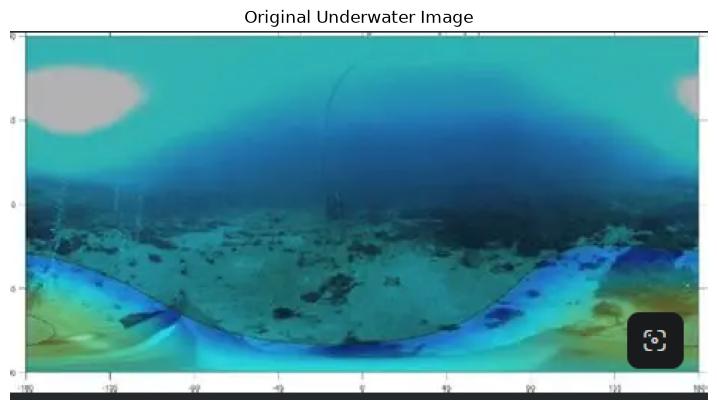

Image dimensions: (248, 469, 3)


In [5]:

image_path = Path("sample_images/underwater.jpg")

if not image_path.exists():
    raise FileNotFoundError(
        "Please add sample_images/underwater.jpg "
        "to your project folder."
    )

with Image.open(image_path) as im:
    original = np.array(
        ImageOps.exif_transpose(im).convert("RGB")
    )

plt.figure(figsize=(9, 5))
plt.imshow(original)
plt.title("Original Underwater Image")
plt.axis("off")
plt.show()

print("Image dimensions:", original.shape)


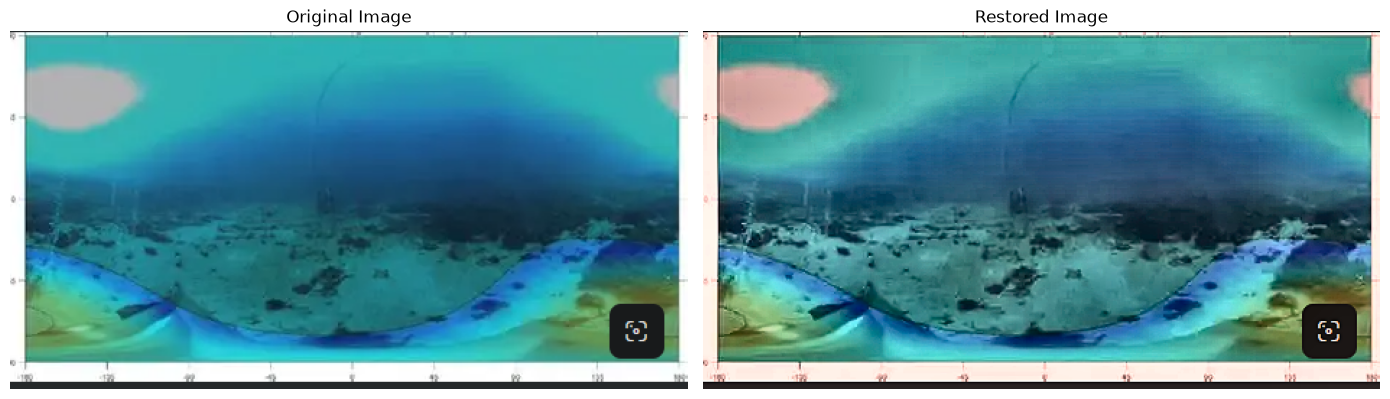

In [8]:
#Restore and compare

restored = restore_underwater_image(
    original,
    color_strength=0.5,
    contrast_strength=2.0,
    sharpening_strength=0.4,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(restored)
axes[1].set_title("Restored Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
#Save the result

output_path = Path("restored_underwater.png")
Image.fromarray(restored).save(output_path)

print("Restored image saved to:", output_path.resolve())


Restored image saved to: C:\Users\student\Desktop\AquaRestore_Project\restored_underwater.png



## Results and Discussion

The original and enhanced images are compared visually. The
algorithm applies color correction, local contrast enhancement,
and sharpening. The result depends on the original image.

## Limitations

Traditional image enhancement cannot guarantee the recovery of
true underwater colors or details that were lost during capture.
Excessive correction can also amplify noise or produce artifacts.

## Conclusion

The project demonstrates an underwater image enhancement pipeline
and integrates the same processing method into a Streamlit web app.
